# Week 4 – Survey Data Insights
**Goal:** clean a survey dataset, calculate response percentages, compare groups, look at trends over time, and summarise findings that the data supports.

**Data:** a synthetic employee survey (3 quarterly rounds: Jan, Apr, Jul 2026) created by `scripts/generate_sample_survey.py`. It is sample data, not real people.

**Survey questions:** Q1–Q5 are 1–5 ratings, Q6 is likelihood to recommend (0–10), Q7–Q8 are single choice, Q9 is multiple choice, Q10 is an open comment. Full list in `docs/survey_questions.md`.

**Rules followed:** keep the raw file unchanged; show the number of responses (n) with every result; mark small groups (n < 30) as less reliable; look for clear differences, not tiny changes; remove personal details.

In [1]:
import json, os, re, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats

sys.path.append("../dashboard")
from survey_calcs import *      # shared calculations (same code the dashboard uses)

pd.set_option("display.max_columns", 40); pd.set_option("display.width", 160)
os.makedirs("../charts", exist_ok=True)
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE, "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True, "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.titlecolor": INK, "axes.titlelocation": "left", "font.size": 10, "text.color": INK2})
def save(fig, name):
    fig.tight_layout(); fig.savefig(f"../charts/{name}.png", dpi=150); plt.show()

## 1. Load and inspect the raw data (the raw file is never edited)

In [2]:
raw = pd.read_csv("../data/raw_survey_responses.csv", dtype=str, keep_default_na=False).replace("", np.nan)
print("Shape:", raw.shape)
display(raw.head(5))
print("\nPersonal-detail columns present:", ["respondent_name", "email", "phone"])
print("\nBlank answers per column:"); print(raw.isna().sum()[raw.isna().sum() > 0])
print("\nExact duplicate rows:", raw.duplicated().sum())
print("Department spellings:", sorted(raw["department"].dropna().unique()))
print("Location spellings:", sorted(raw["location"].dropna().unique()))
print("Q8 spellings:", sorted(raw["q8_stay_next_12_months"].dropna().unique()))
print("Sample rating values typed as text:", raw["q2_work_life_balance"][~raw["q2_work_life_balance"].fillna("1").str.fullmatch(r"\d")].head(5).tolist())

Shape: (456, 19)


,response_id,timestamp,respondent_name,email,phone,department,location,age,tenure,q1_overall_satisfaction,q2_work_life_balance,q3_manager_support,q4_career_growth,q5_compensation_fairness,q6_recommend,q7_workload,q8_stay_next_12_months,q9_valued_benefits,q10_comment
0,RSP-9028,21/01/2026 04:38,Ananya Joshi,ananya.joshi29@example.com,+91 932863 87119,Engineering,Pune,32,Less than 1 year,5,5,5,4,2,8,Very manageable,Yes,Flexible hours; Performance bonus,Leadership should share company plans more ope...
1,RSP-0356,"Jul 25, 2026 11:57 AM",Neha Patel,neha.patel356@example.com,+91 937212 69589,Engineering,Remote,36,3+ years,3,3,5,5,2,8,Often overwhelming,not sure,Flexible hours; Learning budget,NaN
2,RSP-0005,"Jan 24, 2026 11:15 AM",Sneha Menon,sneha.menon5@example.com,+91 909953 45197,Finance,Bengaluru,34,1-3 years,3,1,5,5,3,6,Often overwhelming,No,Flexible hours; Health insurance,"Workload gets too heavy at month end, we need ..."
3,RSP-0086,"Jan 14, 2026 04:53 PM",Meera Patel,meera.patel86@example.com,+91 945642 75297,Support,Bengaluru,33,Less than 1 year,4,3,4,3,4,6,Sometimes overwhelming,Yes,Health insurance; Flexible hours,NaN
4,RSP-0013,29/01/2026 19:20,Priya Khan,priya.khan13@example.com,+91 904978 71675,Support,Pune,42,1-3 years,2,3,4,2,3,6,Sometimes overwhelming,No,Remote work; Wellness programs; Performance bonus,NaN



Personal-detail columns present: ['respondent_name', 'email', 'phone']

Blank answers per column:
department                    8
age                          10
q1_overall_satisfaction       8
q2_work_life_balance          6
q3_manager_support           20
q4_career_growth             17
q5_compensation_fairness     21
q6_recommend                 23
q7_workload                  27
q8_stay_next_12_months       15
q9_valued_benefits           29
q10_comment                 180
dtype: int64

Exact duplicate rows: 12
Department spellings: ['Engineering', 'Engineering ', 'FINANCE', 'Finance', 'Finance ', 'HR & ADMIN', 'HR & Admin', 'HR & Admin ', 'SALES', 'SUPPORT', 'Sales', 'Sales ', 'Support', 'Support ', 'engineering', 'finance', 'sales', 'support']
Location spellings: ['BENGALURU', 'Bangalore', 'Bengaluru', 'Bengaluru ', 'Hyderabad', 'Pune', 'Pune ', 'Remote', 'Remote ', 'bangalore', 'bengaluru', 'pune']
Q8 spellings: ['NO', 'NOT SURE', 'No', 'No ', 'Not sure', 'Not sure ', 'YES', 'Y

## 2. Clean the data
Each step is logged with the number of rows or values it affected. Blank answers are kept as blanks (not guessed) and are left out of that question's percentages.

In [3]:
log = []
df = raw.copy()
ratings = list(RATING_QUESTIONS)

# 1) exact duplicate rows
n = df.duplicated().sum(); df = df.drop_duplicates().copy()
log.append(("Remove exact duplicate responses", int(n)))

# 2) test submissions
is_test = df["respondent_name"].str.lower().eq("test") | df["email"].str.contains("test@", na=False)
log.append(("Remove test submissions (name 'test' / test e-mail)", int(is_test.sum()))); df = df[~is_test].copy()

# 3) timestamps in mixed formats -> datetime, then survey round
def parse_ts(s):
    for fmt in ("%Y-%m-%d %H:%M:%S", "%d/%m/%Y %H:%M", "%b %d, %Y %I:%M %p"):
        try: return pd.to_datetime(s, format=fmt)
        except (ValueError, TypeError): pass
    return pd.NaT
iso = df["timestamp"].str.fullmatch(r"\d{4}-\d{2}-\d{2} \d{2}:\d{2}:\d{2}")
df["date"] = df["timestamp"].map(parse_ts)
log.append(("Convert timestamps in mixed formats to dates", int((~iso).sum())))
df["round_no"] = df["date"].dt.month.map({1: 1, 4: 2, 7: 3}).astype(int)
df["survey_round"] = df["round_no"].map({1: "Round 1 (Jan 2026)", 2: "Round 2 (Apr 2026)", 3: "Round 3 (Jul 2026)"})

# 4) standardise text answers
canon = lambda options: {o.lower(): o for o in options}
def standardise(col, options, extra=None):
    m = canon(options); m.update(extra or {})
    cleaned = df[col].str.strip().str.lower().map(m)
    changed = int((df[col].notna() & (df[col] != cleaned)).sum()); df[col] = cleaned
    return changed
log.append(("Standardise department spelling/case", standardise("department", ["Engineering", "Sales", "Support", "HR & Admin", "Finance"])))
log.append(("Standardise location spelling/case (Bangalore -> Bengaluru)", standardise("location", ["Bengaluru", "Pune", "Hyderabad", "Remote"], {"bangalore": "Bengaluru"})))
log.append(("Standardise Q8 answers (yes / YES / Yes -> Yes)", standardise("q8_stay_next_12_months", STAY_ORDER)))
before = df["q9_valued_benefits"].copy()
df["q9_valued_benefits"] = df["q9_valued_benefits"].map(lambda v: np.nan if pd.isna(v) else "; ".join(p.strip().capitalize() for p in v.split(";") if p.strip()))
df["q9_valued_benefits"] = df["q9_valued_benefits"].replace({"Hr": "HR"})
log.append(("Standardise benefit choices (spacing/case)", int((before.notna() & (before != df["q9_valued_benefits"])).sum())))

# 5) ratings -> numbers; impossible values become 'no response'
WORDS = {"one": 1, "two": 2, "three": 3, "four": 4, "five": 5}
def to_number(v):
    if pd.isna(v): return np.nan
    s = str(v).strip().lower()
    m = re.match(r"^(-?\d+(?:\.\d+)?)", s)
    return float(m.group(1)) if m else float(WORDS.get(s, np.nan))
text_fixed = invalid = 0
for col, (lo, hi) in {**{c: (1, 5) for c in ratings}, "q6_recommend": (0, 10)}.items():
    nums = df[col].map(to_number)
    text_fixed += int((df[col].notna() & ~df[col].fillna("0").str.fullmatch(r"\d+")).sum())
    bad = nums.notna() & ((nums < lo) | (nums > hi) | (nums != nums.round()))
    invalid += int(bad.sum()); df[col] = nums.where(~bad)
log.append(("Convert ratings typed as text ('4 - Agree', 'Four', '4.0') to numbers", text_fixed))
log.append(("Impossible rating values (0, 6, 55, -1, 11) set to 'no response'", invalid))

# 6) same person submitting twice in one round -> keep the first submission
before = len(df)
df = df.sort_values("date").drop_duplicates(subset=["email", "round_no"], keep="first").copy()
log.append(("Remove repeat submissions (same e-mail in the same round, keep first)", before - len(df)))

# 7) incomplete responses: fewer than half of Q1-Q9 answered
answered = df[ratings + ["q6_recommend", "q7_workload", "q8_stay_next_12_months", "q9_valued_benefits"]].notna().sum(axis=1)
inc = answered < 5; log.append(("Remove incomplete responses (fewer than 5 of 9 questions answered)", int(inc.sum()))); df = df[~inc].copy()

# 8) age -> age groups; impossible/missing ages -> 'Not specified'
age = pd.to_numeric(df["age"], errors="coerce")
bad_age = age.notna() & ((age < 18) | (age > 70))
df["age_group"] = pd.cut(age.where(~bad_age), [17, 24, 34, 44, 120], labels=["18-24", "25-34", "35-44", "45+"]).astype(object).fillna("Not specified")
log.append(("Impossible ages (5, 0, 150) and blank ages -> 'Not specified'", int(bad_age.sum() + age.isna().sum())))
n = df["department"].isna().sum(); df["department"] = df["department"].fillna("Not specified")
log.append(("Blank department labelled 'Not specified'", int(n)))

# 9) tag open-text comments by theme (keyword rules)
THEMES = [("Positive", ["happy", "great colleagues", "keep up", "culture"]), ("Workload", ["workload", "overtime", "deadline", "urgent", "month end"]),
          ("Career growth", ["promotion", "training", "learn", "certification", "mentor", "career"]), ("Pay", ["salary", "pay ", "bonus"]),
          ("Communication", ["leadership", "management", "updates", "meetings"]), ("Flexibility", ["flexible", "hybrid", "working hours"]),
          ("Tools", ["tools", "software", "equipment"])]
def theme(c):
    if pd.isna(c): return np.nan
    t = c.lower()
    return next((name for name, kws in THEMES if any(k in t for k in kws)), "Other")
df["comment"] = df["q10_comment"]; df["comment_theme"] = df["comment"].map(theme)
log.append(("Tag open-text comments by theme", int(df["comment"].notna().sum())))

# 10) remove personal details; derived columns
df["nps_category"] = pd.cut(df["q6_recommend"], [-1, 6, 8, 10], labels=["Detractor", "Passive", "Promoter"]).astype(object)
df["benefits"] = df["q9_valued_benefits"]
n_pii = 3; log.append(("Remove personal details (name, e-mail, phone) from the cleaned file", n_pii))
clean = df.rename(columns={"q7_workload": "q7_workload", "q8_stay_next_12_months": "q8_stay_next_12_months"})[[
    "response_id", "date", "round_no", "survey_round", "department", "location", "age_group", "tenure"] + ratings + [
    "q6_recommend", "nps_category", "q7_workload", "q8_stay_next_12_months", "benefits", "comment", "comment_theme"]].sort_values("response_id").reset_index(drop=True)
for b in ["Health insurance", "Flexible hours", "Learning budget", "Remote work", "Paid leave", "Performance bonus", "Wellness programs"]:
    clean["benefit_" + b.lower().replace(" ", "_")] = clean["benefits"].fillna("").str.contains(b).astype(int)

assert not clean.duplicated("response_id").any()
assert not {"respondent_name", "email", "phone"} & set(clean.columns)
assert clean[ratings].stack().dropna().between(1, 5).all() and clean["q6_recommend"].dropna().between(0, 10).all()
clean.to_csv("../data/cleaned_survey_data.csv", index=False)
cleaning_log = pd.DataFrame(log, columns=["Cleaning step", "Rows / values affected"])
display(cleaning_log)
print(f"Rows: {len(raw)} raw -> {len(clean)} valid responses")

,Cleaning step,Rows / values affected
0,Remove exact duplicate responses,12
1,Remove test submissions (name 'test' / test e-...,3
2,Convert timestamps in mixed formats to dates,294
3,Standardise department spelling/case,25
4,Standardise location spelling/case (Bangalore ...,60
5,Standardise Q8 answers (yes / YES / Yes -> Yes),62
6,Standardise benefit choices (spacing/case),56
7,"Convert ratings typed as text ('4 - Agree', 'F...",30
8,"Impossible rating values (0, 6, 55, -1, 11) se...",7
9,Remove repeat submissions (same e-mail in the ...,6


Rows: 456 raw -> 420 valid responses


## 3. Response counts and percentages for every question

In [4]:
valid = clean
rows = []
for col, label in RATING_QUESTIONS.items():
    d = single_choice(valid.assign(**{col: valid[col].astype("Int64").astype("string")}), col, ["1", "2", "3", "4", "5"])
    rows += [(label, f"Rating {a}", n, t, p) for a, n, t, p in zip(d.answer, d.n, d.total, d.pct)]
d = single_choice(valid.assign(rec=valid["nps_category"]), "rec", ["Promoter", "Passive", "Detractor"])
rows += [("Likelihood to recommend (0-10)", a, n, t, p) for a, n, t, p in zip(d.answer, d.n, d.total, d.pct)]
for col, label, order in [("q7_workload", "Workload", WORKLOAD_ORDER), ("q8_stay_next_12_months", "Plan to stay 12 months", STAY_ORDER)]:
    d = single_choice(valid, col, order); rows += [(label, a, n, t, p) for a, n, t, p in zip(d.answer, d.n, d.total, d.pct)]
d = multi_choice(valid); rows += [("Valued benefits (pick up to 3; % of respondents)", a, n, t, p) for a, n, t, p in zip(d.answer, d.n, d.total, d.pct)]
resp = pd.DataFrame(rows, columns=["question", "answer", "responses", "valid_n", "response_pct"])
resp["response_pct"] = resp["response_pct"].round(1)
resp.to_csv("../data/response_summary.csv", index=False)
display(resp)

,question,answer,responses,valid_n,response_pct
0,Overall satisfaction,Rating 1,2,415,0.5
1,Overall satisfaction,Rating 2,25,415,6.0
2,Overall satisfaction,Rating 3,113,415,27.2
3,Overall satisfaction,Rating 4,180,415,43.4
4,Overall satisfaction,Rating 5,95,415,22.9
5,Work-life balance,Rating 1,6,413,1.5
6,Work-life balance,Rating 2,44,413,10.7
7,Work-life balance,Rating 3,146,413,35.4
8,Work-life balance,Rating 4,157,413,38.0
9,Work-life balance,Rating 5,60,413,14.5


## 4. Rating questions: averages, most common answer, favourable %

,question,column,n,mean,median,most_common,pct_favourable
0,Overall satisfaction,q1_overall_satisfaction,415,3.82,4.0,4,66.27
1,Work-life balance,q2_work_life_balance,413,3.54,4.0,4,52.54
2,Manager support,q3_manager_support,415,3.87,4.0,4,67.95
3,Career growth,q4_career_growth,416,3.48,3.0,3,49.28
4,Compensation fairness,q5_compensation_fairness,413,3.08,3.0,3,32.93


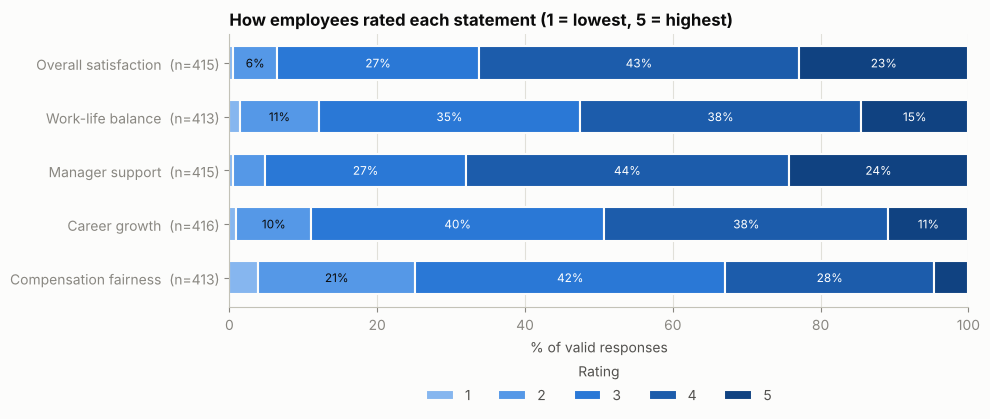

In [5]:
rs = rating_summary(valid); display(rs.round(2))
dist = rating_distribution(valid)
fig, ax = plt.subplots(figsize=(10, 4.4))
labels = list(RATING_QUESTIONS.values())
left = np.zeros(len(labels))
for r in [1, 2, 3, 4, 5]:
    vals = np.array([dist[(dist.question == q) & (dist.rating == r)]["pct"].iloc[0] for q in labels])
    ax.barh(labels, vals, left=left, color=ORDINAL5[r - 1], edgecolor=SURFACE, linewidth=1.5, label=f"{r}", height=0.62)
    for y, (l, v) in enumerate(zip(left, vals)):
        if v >= 6: ax.text(l + v / 2, y, f"{v:.0f}%", ha="center", va="center", fontsize=8.5, color=INK if r <= 2 else "white")
    left += vals
ax.set_yticks(range(len(labels))); ax.set_yticklabels([f"{q}  (n={int(n)})" for q, n in zip(labels, rs["n"])])
ax.invert_yaxis(); ax.set_xlim(0, 100); ax.grid(axis="y", visible=False); ax.set_xlabel("% of valid responses")
ax.set_title("How employees rated each statement (1 = lowest, 5 = highest)")
ax.legend(title="Rating", ncol=5, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.16))
save(fig, "01_rating_distribution")

## 5. Recommend score (NPS) and satisfaction

{'score': 25.8, 'promoters': 193, 'passives': 131, 'detractors': 87, 'n': 411}


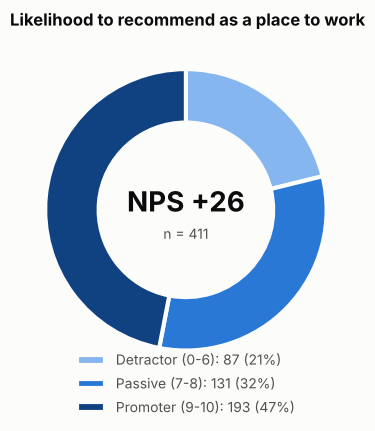

,score,n
Round 1 (Jan 2026),19.5,133.0
Round 2 (Apr 2026),25.4,138.0
Round 3 (Jul 2026),32.1,140.0


,score,n
Support,-4.3,92.0
Not specified,25.0,8.0
HR & Admin,32.1,53.0
Finance,32.8,58.0
Sales,34.8,69.0
Engineering,36.6,131.0


In [6]:
nps_all = nps(valid["q6_recommend"])
print({k: round(v, 1) if isinstance(v, float) else v for k, v in nps_all.items()})
fig, ax = plt.subplots(figsize=(6.4, 4.4))
parts = [("Detractor (0-6)", nps_all["detractors"], ORDINAL5[0]), ("Passive (7-8)", nps_all["passives"], ORDINAL5[2]), ("Promoter (9-10)", nps_all["promoters"], ORDINAL5[4])]
ax.pie([p[1] for p in parts], colors=[p[2] for p in parts], startangle=90, counterclock=False, wedgeprops=dict(width=0.38, edgecolor=SURFACE, linewidth=3))
ax.text(0, 0.06, f"NPS {nps_all['score']:+.0f}", ha="center", va="center", fontsize=20, fontweight="bold", color=INK)
ax.text(0, -0.17, f"n = {nps_all['n']}", ha="center", va="center", fontsize=10, color=INK2)
ax.legend([f"{p[0]}: {p[1]} ({p[1] / nps_all['n'] * 100:.0f}%)" for p in parts], frameon=False, loc="lower center", bbox_to_anchor=(0.5, -0.12))
ax.set_title("Likelihood to recommend as a place to work"); ax.grid(False)
save(fig, "04_nps_breakdown")
nps_round = pd.DataFrame({r: nps(g["q6_recommend"]) for r, g in valid.groupby("survey_round")}).T[["score", "n"]]
nps_dept = pd.DataFrame({r: nps(g["q6_recommend"]) for r, g in valid.groupby("department")}).T[["score", "n"]].sort_values("score")
display(nps_round.round(1)); display(nps_dept.round(1))

## 6. Compare groups
For each question and group type we find the gap between the highest and lowest group average, using only groups with at least 30 responses, and test it with a Kruskal-Wallis test (suited to 1–5 ratings). A difference is called **clear** only if the gap is at least 0.30 points **and** p < 0.05.

In [7]:
comp = []
for gcol, glabel in GROUPS.items():
    for qcol, qlabel in RATING_QUESTIONS.items():
        g = group_means(valid[valid[gcol] != "Not specified"], gcol, qcol)
        g = g[g["n"] >= LOW_N]
        if len(g) < 2: continue
        samples = [valid.loc[(valid[gcol] == a), qcol].dropna() for a in g[gcol]]
        p = stats.kruskal(*samples).pvalue
        hi, lo = g.loc[g["mean"].idxmax()], g.loc[g["mean"].idxmin()]
        gap = hi["mean"] - lo["mean"]
        comp.append(dict(group_type=glabel, question=qlabel, highest=hi[gcol], highest_mean=hi["mean"], highest_n=int(hi["n"]),
                         lowest=lo[gcol], lowest_mean=lo["mean"], lowest_n=int(lo["n"]), gap=gap, p_value=p, clear=bool(gap >= 0.30 and p < 0.05)))
comp = pd.DataFrame(comp).sort_values(["clear", "gap"], ascending=False)
display(comp.round(3))
print("Clear differences:", int(comp["clear"].sum()), "of", len(comp), "comparisons")

,group_type,question,highest,highest_mean,highest_n,lowest,lowest_mean,lowest_n,gap,p_value,clear
0,Department,Overall satisfaction,HR & Admin,4.074,54,Support,3.308,91,0.766,0.000,True
4,Department,Compensation fairness,Sales,3.500,72,Engineering,2.763,131,0.737,0.000,True
1,Department,Work-life balance,HR & Admin,3.943,53,Support,3.278,90,0.666,0.000,True
2,Department,Manager support,Sales,4.127,71,Support,3.598,92,0.529,0.004,True
3,Department,Career growth,HR & Admin,3.679,53,Support,3.231,91,0.448,0.009,True
15,Tenure,Overall satisfaction,Less than 1 year,4.008,133,3+ years,3.609,128,0.398,0.001,True
6,Location,Work-life balance,Remote,3.649,111,Hyderabad,3.391,69,0.257,0.182,False
11,Age group,Work-life balance,35-44,3.651,126,18-24,3.433,60,0.217,0.105,False
5,Location,Overall satisfaction,Pune,3.944,90,Bengaluru,3.733,146,0.212,0.330,False
13,Age group,Career growth,18-24,3.542,59,35-44,3.389,126,0.153,0.389,False


Clear differences: 6 of 20 comparisons


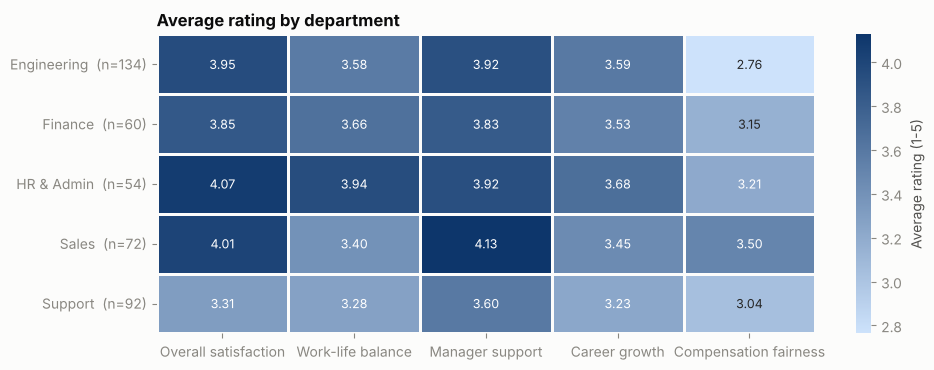

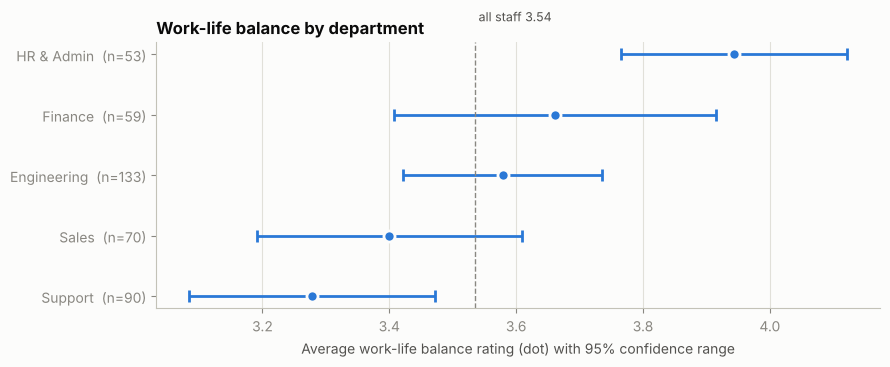

In [8]:
heat = pd.DataFrame({q: valid[valid.department != "Not specified"].groupby("department")[c].mean() for c, q in RATING_QUESTIONS.items()})
ns = valid[valid.department != "Not specified"].groupby("department").size()
heat.index = [f"{d}  (n={ns[d]})" for d in heat.index]
fig, ax = plt.subplots(figsize=(10, 3.8))
sns.heatmap(heat, cmap=LinearSegmentedColormap.from_list("seq", SEQ), annot=True, fmt=".2f", linewidths=2, linecolor=SURFACE,
            cbar_kws={"label": "Average rating (1-5)"}, annot_kws={"size": 9}, ax=ax)
ax.set_title("Average rating by department"); ax.set_xlabel(""); ax.set_ylabel(""); ax.grid(False)
plt.setp(ax.get_xticklabels(), rotation=0)
save(fig, "02_department_heatmap")

g = group_means(valid[valid.department != "Not specified"], "department", "q2_work_life_balance").sort_values("mean")
overall = valid["q2_work_life_balance"].mean()
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.errorbar(g["mean"], range(len(g)), xerr=g["ci"], fmt="o", color=BLUE, ecolor=BLUE, elinewidth=2, capsize=4, ms=8, mec=SURFACE, mew=2)
ax.axvline(overall, color=MUTED, ls="--", lw=1); ax.text(overall, len(g) - 0.45, f" all staff {overall:.2f}", color=INK2, fontsize=9)
ax.set_yticks(range(len(g))); ax.set_yticklabels([f"{d}  (n={n})" for d, n in zip(g["department"], g["n"])])
ax.grid(axis="y", visible=False); ax.set_xlabel("Average work-life balance rating (dot) with 95% confidence range")
ax.set_title("Work-life balance by department")
save(fig, "08_work_life_balance_by_department")

## 7. Trends across the three survey rounds
Each round surveyed different employees (anonymous), so a trend compares group averages, not the same people. A change is called clear if Round 3 differs from Round 1 by at least 0.15 points with p < 0.05 (Mann-Whitney test).

,question,round1,round3,change,p_value,clear
0,Overall satisfaction,3.776,3.910,0.134,0.166,False
1,Work-life balance,3.526,3.596,0.069,0.584,False
2,Manager support,3.774,4.021,0.247,0.013,True
3,Career growth,3.462,3.542,0.080,0.402,False
4,Compensation fairness,3.105,2.986,-0.119,0.264,False


survey_round
Round 1 (Jan 2026)    135
Round 2 (Apr 2026)    140
Round 3 (Jul 2026)    145
Name: responses per round, dtype: int64

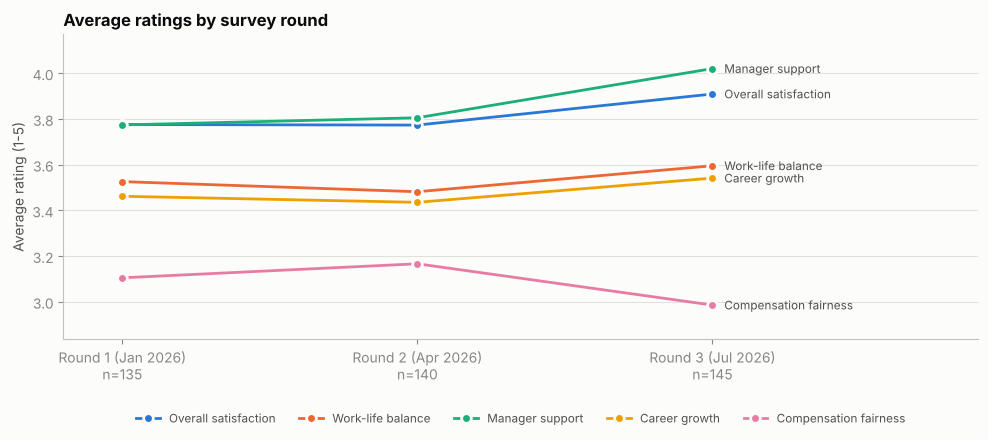

In [9]:
tr = trend(valid)
piv = tr.pivot(index="question", columns="survey_round", values="mean").reindex(labels)
rn = valid.groupby("survey_round").size()
rows = []
for c, q in RATING_QUESTIONS.items():
    a, b = valid.loc[valid.round_no == 1, c].dropna(), valid.loc[valid.round_no == 3, c].dropna()
    p = stats.mannwhitneyu(a, b).pvalue
    rows.append(dict(question=q, round1=a.mean(), round3=b.mean(), change=b.mean() - a.mean(), p_value=p, clear=bool(abs(b.mean() - a.mean()) >= 0.15 and p < 0.05)))
trend_tbl = pd.DataFrame(rows); display(trend_tbl.round(3)); display(rn.rename("responses per round"))

fig, ax = plt.subplots(figsize=(10, 4.6))
xs = list(piv.columns)
for i, q in enumerate(labels):
    ax.plot(range(3), piv.loc[q].values, color=SERIES[i], lw=2, marker="o", ms=7, mec=SURFACE, mew=2, label=q)
    ax.text(2.04, piv.loc[q].values[2], q, va="center", fontsize=8.5, color=INK2)
ax.set_xticks(range(3)); ax.set_xticklabels([f"{x}\nn={rn[x]}" for x in xs]); ax.set_xlim(-0.2, 2.9)
ax.set_ylim(piv.values.min() - 0.15, piv.values.max() + 0.15); ax.set_ylabel("Average rating (1-5)")
ax.grid(axis="x", visible=False); ax.set_title("Average ratings by survey round")
ax.legend(frameon=False, ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.2), fontsize=8.5)
save(fig, "03_trend_by_round")

## 8. Single-choice, multiple-choice and comments

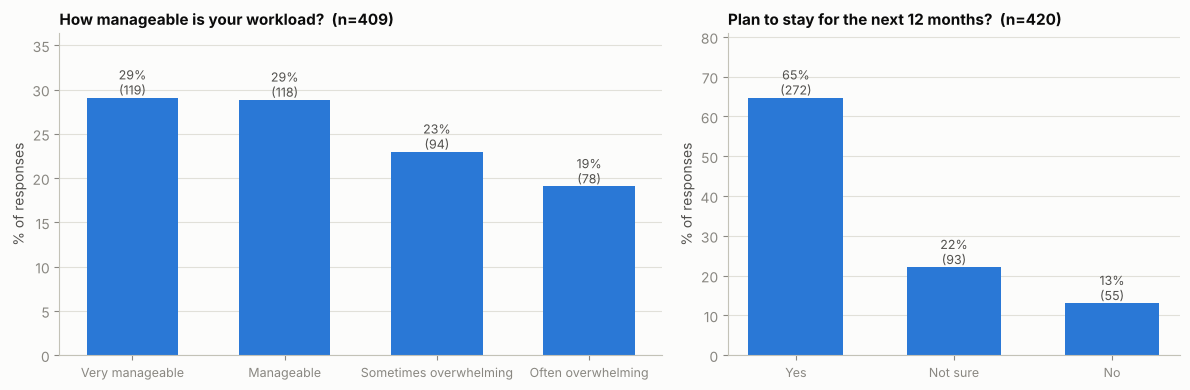

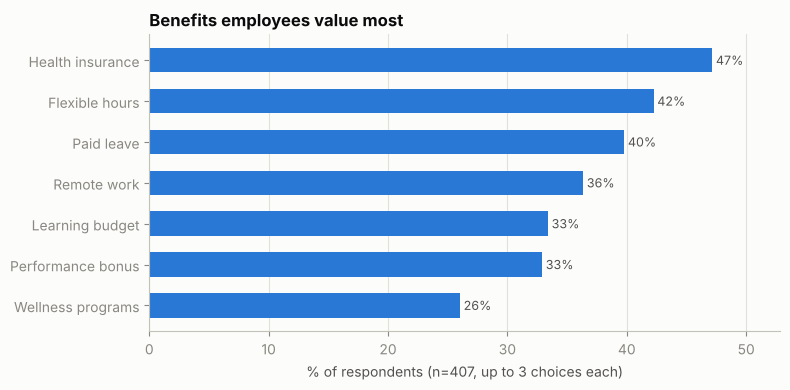

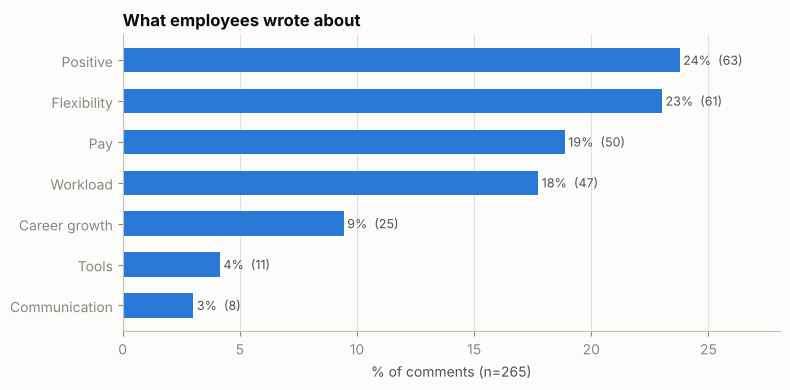

265 of 420 respondents left a comment (63%)


In [10]:
wl = single_choice(valid, "q7_workload", WORKLOAD_ORDER); st = single_choice(valid, "q8_stay_next_12_months", STAY_ORDER)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [4, 3]})
for ax, d, ttl in [(axes[0], wl, "How manageable is your workload?"), (axes[1], st, "Plan to stay for the next 12 months?")]:
    ax.bar(d["answer"], d["pct"], color=BLUE, width=0.6)
    for x, (p, n) in enumerate(zip(d["pct"], d["n"])): ax.text(x, p, f"{p:.0f}%\n({n})", ha="center", va="bottom", fontsize=9, color=INK2)
    ax.set_title(f"{ttl}  (n={d['total'].iloc[0]})", fontsize=11); ax.grid(axis="x", visible=False); ax.set_ylim(0, d["pct"].max() * 1.25); ax.set_ylabel("% of responses")
    plt.setp(ax.get_xticklabels(), fontsize=9)
save(fig, "05_workload_and_stay_intent")

ben = multi_choice(valid).sort_values("pct")
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(ben["answer"], ben["pct"], color=BLUE, height=0.6)
for y, p in enumerate(ben["pct"]): ax.text(p, y, f" {p:.0f}%", va="center", fontsize=9, color=INK2)
ax.grid(axis="y", visible=False); ax.margins(x=0.12); ax.set_xlabel(f"% of respondents (n={ben['total'].iloc[0]}, up to 3 choices each)")
ax.set_title("Benefits employees value most")
save(fig, "06_valued_benefits")

has_c = valid["comment"].notna().sum()
th = valid["comment_theme"].value_counts(); th_pct = (th / has_c * 100).sort_values()
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(th_pct.index, th_pct.values, color=BLUE, height=0.6)
for y, (p, k) in enumerate(zip(th_pct.values, th_pct.index)): ax.text(p, y, f" {p:.0f}%  ({th[k]})", va="center", fontsize=9, color=INK2)
ax.grid(axis="y", visible=False); ax.margins(x=0.18); ax.set_xlabel(f"% of comments (n={has_c})")
ax.set_title("What employees wrote about")
save(fig, "07_comment_themes")
print(f"{has_c} of {len(valid)} respondents left a comment ({has_c / len(valid):.0%})")

## 9. Save the numbers used in the report and the cleaning log

In [11]:
r1 = lambda x, n=1: round(float(x), n)
dept_nps = nps_dept["score"]
ins = {
    "rows_raw": int(len(raw)), "rows_clean": int(len(clean)),
    "responses_per_round": {k: int(v) for k, v in rn.items()},
    "ratings": [dict(question=r.question, n=int(r.n), mean=r1(r["mean"], 2), most_common=int(r.most_common), favourable=r1(r.pct_favourable)) for _, r in rs.iterrows()],
    "nps": {"score": r1(nps_all["score"]), "n": nps_all["n"], "promoter_pct": r1(100 * nps_all["promoters"] / nps_all["n"]), "detractor_pct": r1(100 * nps_all["detractors"] / nps_all["n"]),
            "by_round": {k: r1(v) for k, v in nps_round["score"].items()}},
    "clear_differences": [dict(group_type=r.group_type, question=r.question, highest=r.highest, highest_mean=r1(r.highest_mean, 2), highest_n=r.highest_n,
                               lowest=r.lowest, lowest_mean=r1(r.lowest_mean, 2), lowest_n=r.lowest_n, gap=r1(r.gap, 2), p=float(r.p_value)) for _, r in comp[comp.clear].iterrows()],
    "no_clear_difference": sorted(set(comp.loc[~comp.clear, "group_type"]) - set(comp.loc[comp.clear, "group_type"])),
    "comparisons_total": int(len(comp)),
    "trend": [dict(question=r.question, round1=r1(r.round1, 2), round3=r1(r.round3, 2), change=r1(r.change, 2), clear=bool(r.clear)) for _, r in trend_tbl.iterrows()],
    "workload": {r.answer: r1(r.pct) for r in wl.itertuples()}, "stay": {r.answer: r1(r.pct) for r in st.itertuples()},
    "workload_n": int(wl["total"].iloc[0]), "stay_n": int(st["total"].iloc[0]),
    "benefits": [[r.answer, r1(r.pct)] for r in multi_choice(valid).itertuples()], "benefits_n": int(multi_choice(valid)["total"].iloc[0]),
    "comment_n": int(has_c), "comment_rate": r1(100 * has_c / len(valid)), "themes": [[k, int(v), r1(100 * v / has_c)] for k, v in th.items()],
    "dept_n": {k: int(v) for k, v in valid.groupby("department").size().items()},
    "support_workload_overwhelming": r1(100 * valid.loc[valid.department == "Support", "q7_workload"].isin(["Sometimes overwhelming", "Often overwhelming"]).mean()),
    "other_workload_overwhelming": r1(100 * valid.loc[valid.department.isin(["Engineering", "Sales", "HR & Admin", "Finance"]), "q7_workload"].isin(["Sometimes overwhelming", "Often overwhelming"]).mean()),
    "cleaning_log": [[a, b] for a, b in log],
}
json.dump(ins, open("../data/insights.json", "w"), indent=2)

lines = ["# Data cleaning log", "", f"Raw file: `data/raw_survey_responses.csv` ({len(raw)} rows, left unchanged). Cleaned file: `data/cleaned_survey_data.csv` ({len(clean)} valid responses).", "",
         "| # | Step | Rows / values affected |", "|---|---|---|"] + [f"| {i} | {a} | {b} |" for i, (a, b) in enumerate(log, 1)] + [
         "", "## Decisions and assumptions", "- Blank answers are kept as blank and excluded from that question's percentages; nothing is guessed.",
         "- A repeat submission is the same e-mail address in the same survey round; the first one is kept. E-mail is used only for this check and then removed.",
         "- A response is incomplete if fewer than 5 of the 9 closed questions (Q1-Q9) were answered.",
         "- Ratings outside the allowed range (Q1-Q5: 1-5, Q6: 0-10) are treated as typing errors and set to no response.",
         "- Ages outside 18-70 are treated as errors; the response stays in the data with age group 'Not specified'.",
         "- Comments are tagged by simple keyword rules, so themes are approximate; one theme per comment.",
         "- Personal details (name, e-mail, phone) are dropped from the cleaned file; the dashboard never uses them."]
open("../docs/data_cleaning_log.md", "w").write("\n".join(lines) + "\n")
print(json.dumps({k: ins[k] for k in ["rows_raw", "rows_clean", "nps", "no_clear_difference", "comparisons_total"]}, indent=1))
print(len(ins["clear_differences"]), "clear differences")

{
 "rows_raw": 456,
 "rows_clean": 420,
 "nps": {
  "score": 25.8,
  "n": 411,
  "promoter_pct": 47.0,
  "detractor_pct": 21.2,
  "by_round": {
   "Round 1 (Jan 2026)": 19.5,
   "Round 2 (Apr 2026)": 25.4,
   "Round 3 (Jul 2026)": 32.1
  }
 },
 "no_clear_difference": [
  "Age group",
  "Location"
 ],
 "comparisons_total": 20
}
6 clear differences
